# Pandas paso a paso: del notebook a Reflex

Este cuaderno reproduce el recorrido de `Ejercicio991Reflex/pandas_data_app.py` con el mismo `data/orders.csv`. Ejecuta las celdas de arriba abajo con **Run All / Ejecutar todo**. Selecciona el intérprete `.venv/bin/python` del directorio EjerciciosPython.

En Reflex un evento modifica el estado y refresca la pantalla. Aquí modificas variables y vuelves a ejecutar las celdas: las gráficas son instantáneas, no se actualizan solas.

| Notebook | Reflex |
|---|---|
| Leer bytes y validar | `load_sample` → `read_orders` |
| Variables `region` y `product` | Formulario → `apply_filters` |
| `.loc` y `.str.contains` | `analyze_orders` y `_refresh` |
| Agrupaciones e importes | `PandasAppState._refresh` |
| Matplotlib | Recharts en `pandas_data_app` y `extra_charts` |

Los datos son ficticios; el beneficio bruto no descuenta impuestos ni gastos adicionales.

**Referencias cruzadas:** cada sección indica líneas aproximadas y nombres del archivo Python. En Reflex, los comentarios `NOTEBOOK §N` señalan la sección equivalente. Los rangos se calcularon después de insertar los comentarios; cambiarán si editas el código.

## 1. Preparar el entorno y localizar los archivos
La ruta se resuelve desde la carpeta del proyecto o desde EjerciciosPython. No depende de una ruta absoluta de tu ordenador.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: La constante `DATA_PATH` está en la **línea 21** y los tipos de registro en **líneas 25–32**, `OrderRow`. El notebook añade la búsqueda de carpeta para poder ejecutarse desde VS Code.

In [1]:
from pathlib import Path
from decimal import Decimal
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p if (p / 'data/orders.csv').exists() else p / 'Ejercicio991Reflex'
                for p in candidates
                if (p / 'data/orders.csv').exists() or (p / 'Ejercicio991Reflex/data/orders.csv').exists()), None)
if PROJECT is None:
    raise FileNotFoundError('Abre el notebook dentro de Ejercicio991Reflex o EjerciciosPython.')
sys.path.insert(0, str(PROJECT)) if str(PROJECT) not in sys.path else None
from Ejercicio991Reflex.pandas_data_app import read_orders, analyze_orders, PandasAppState

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
CSV_PATH = PROJECT / 'data/orders.csv'
print('CSV:', CSV_PATH)
print('Python:', sys.executable)

CSV: /home/tvt/MEGA/EjerciciosPython/Ejercicio991Reflex/data/orders.csv
Python: /home/tvt/MEGA/EjerciciosPython/.venv/bin/python


## 2. Cargar y validar
Reutilizamos la función real `read_orders` para que el cuaderno acepte y rechace exactamente los mismos CSV que la aplicación. Después convertimos la lista de diccionarios en un DataFrame.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 46–109**, `read_orders` valida y convierte los datos; **líneas 187–200**, `load_sample` lee los bytes del archivo. En la celda siguiente `read_orders` es la función importada directamente de Reflex.

In [2]:
records = read_orders(CSV_PATH.read_bytes())
frame = pd.DataFrame(records)
print(f'{len(frame)} filas y {len(frame.columns)} columnas')
display(frame.head(8))
display(frame.dtypes.to_frame('Tipo'))

72 filas y 7 columnas


,region,product,units,date,unit_price,unit_cost,channel
0,North,Tea,11,2026-01-05,8.50,3.2,Store
1,North,Coffee,15,2026-01-06,12.00,5.1,Wholesale
2,North,Chocolate,19,2026-01-07,9.75,4.3,Online
3,South,Tea,14,2026-01-10,8.50,3.2,Wholesale
4,South,Coffee,18,2026-01-11,12.00,5.1,Online
5,South,Chocolate,22,2026-01-12,9.75,4.3,Store
6,East,Tea,17,2026-01-15,8.50,3.2,Online
7,East,Coffee,21,2026-01-16,12.00,5.1,Store


,Tipo
region,str
product,str
units,int64
date,str
unit_price,float64
unit_cost,float64
channel,str


## 3. Cambiar los filtros
Equivalen al formulario de Reflex. Cambia `All` por `North`, `South`, `East` o `West`; escribe un fragmento de producto, como `Tea`. Después vuelve a ejecutar desde aquí. Una búsqueda vacía conserva todos los productos.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 228–242**, `apply_filters` recibe `region` y `product` del formulario. El notebook los sustituye por variables editables; no necesita `@rx.event`.

In [3]:
region = 'All'
product = ''

if region not in ['All', 'North', 'South', 'East', 'West']:
    raise ValueError('Región no permitida')

## 4. Entender `.loc`
La máscara contiene un booleano por fila. `.loc[mascara]` conserva las filas con `True` y todas sus columnas. `case=False` ignora mayúsculas; `regex=False` busca texto literal. `.copy()` permite añadir columnas sin modificar el DataFrame original.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 113–133**, `analyze_orders` aplica los filtros de la tabla y el resumen regional. En `_refresh`, **líneas 166–168**, se aplican esos mismos filtros a las series adicionales.

In [4]:
filtered = frame.copy()
if region != 'All':
    filtered = filtered.loc[filtered['region'] == region]
mask = filtered['product'].str.contains(product.strip(), case=False, regex=False)
display(pd.DataFrame({'producto': filtered['product'], 'coincide': mask}).head(10))
filtered = filtered.loc[mask].copy()
print('Registros filtrados:', len(filtered))
display(filtered.head())

,producto,coincide
0,Tea,True
1,Coffee,True
2,Chocolate,True
3,Tea,True
4,Coffee,True
5,Chocolate,True
6,Tea,True
7,Coffee,True
8,Chocolate,True
9,Tea,True


Registros filtrados: 72


,region,product,units,date,unit_price,unit_cost,channel
0,North,Tea,11,2026-01-05,8.50,3.2,Store
1,North,Coffee,15,2026-01-06,12.00,5.1,Wholesale
2,North,Chocolate,19,2026-01-07,9.75,4.3,Online
3,South,Tea,14,2026-01-10,8.50,3.2,Wholesale
4,South,Coffee,18,2026-01-11,12.00,5.1,Online


## 5. Calcular ingresos y beneficio
`units × unit_price` son ingresos; `units × unit_cost` es coste. Convertimos los precios a céntimos enteros antes de multiplicar y sumar, como hace `_refresh`. Se permiten beneficios negativos si el coste supera el precio.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: En `_refresh`, **líneas 170–173**, se calculan ingresos y beneficio. **líneas 266–298**, `metric_card` los presenta como tarjetas; aquí los inspeccionamos en una tabla.

In [5]:
filtered['revenue_cents'] = filtered['units'] * filtered['unit_price'].map(lambda x: round(x * 100))
filtered['profit_cents'] = filtered['revenue_cents'] - filtered['units'] * filtered['unit_cost'].map(lambda x: round(x * 100))
filtered['month'] = filtered['date'].str[:7]
metrics = pd.DataFrame({
    'Indicador': ['Pedidos', 'Unidades', 'Ingresos (€)', 'Beneficio bruto (€)'],
    'Valor': [len(filtered), filtered['units'].sum(), filtered['revenue_cents'].sum()/100,
              filtered['profit_cents'].sum()/100]})
display(metrics)
display(filtered.head())

,Indicador,Valor
0,Pedidos,72.00
1,Unidades,2025.00
2,Ingresos (€),20538.75
3,Beneficio bruto (€),11928.15


,region,product,units,date,unit_price,unit_cost,channel,revenue_cents,profit_cents,month
0,North,Tea,11,2026-01-05,8.50,3.2,Store,9350,5830,2026-01
1,North,Coffee,15,2026-01-06,12.00,5.1,Wholesale,18000,10350,2026-01
2,North,Chocolate,19,2026-01-07,9.75,4.3,Online,18525,10355,2026-01
3,South,Tea,14,2026-01-10,8.50,3.2,Wholesale,11900,7420,2026-01
4,South,Coffee,18,2026-01-11,12.00,5.1,Online,21600,12420,2026-01


## 6. Agrupar los datos
`groupby` reúne las filas con la misma etiqueta y `sum` suma sus valores. `as_index=False` conserva las etiquetas como columnas. Los resúmenes usan todas las filas filtradas; solo la tabla de vista previa se limita a 50.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 113–133**, `analyze_orders` calcula unidades por región. En `_refresh`, **líneas 174–183**, se agrupa por mes, producto y canal. La celda muestra los DataFrames antes de convertirlos.

In [6]:
summary = filtered.groupby('region', as_index=False, sort=True)['units'].sum()
monthly = filtered.loc[filtered['month'] != ''].groupby('month', as_index=False)[['revenue_cents', 'profit_cents']].sum()
monthly['revenue'] = monthly['revenue_cents'] / 100
monthly['profit'] = monthly['profit_cents'] / 100
products = filtered.groupby('product', as_index=False)['units'].sum()
channels = filtered.groupby('channel', as_index=False)['revenue_cents'].sum()
channels['revenue'] = channels['revenue_cents'] / 100
for title, table in [('Por región', summary), ('Por mes', monthly), ('Por producto', products), ('Por canal', channels)]:
    print(title)
    display(table)

Por región


,region,units
0,East,540
1,North,405
2,South,504
3,West,576


Por mes


,month,revenue_cents,profit_cents,revenue,profit
0,2026-01,237950,137910,2379.50,1379.10
1,2026-02,292400,169680,2924.00,1696.80
2,2026-03,325675,189095,3256.75,1890.95
3,2026-04,358950,208510,3589.50,2085.10
4,2026-05,392225,227925,3922.25,2279.25
5,2026-06,446675,259695,4466.75,2596.95


Por producto


,product,units
0,Chocolate,771
1,Coffee,675
2,Tea,579


Por canal


,channel,revenue_cents,revenue
0,Online,684950,6849.50
1,Store,685225,6852.25
2,Wholesale,683700,6837.00


## 7. Dibujar las mismas cuatro gráficas
Matplotlib dibuja aquí; Recharts dibuja en el navegador. Ambas reciben los mismos resúmenes. Los meses sin registros se omiten: no se inventan ventas a cero.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 670–702**, `extra_charts` contiene las gráficas mensual, de productos y de canales. La gráfica regional está en la **línea 525**, dentro de `pandas_data_app`. Aquí Matplotlib dibuja las cuatro juntas; la representación es distinta, los datos son equivalentes.

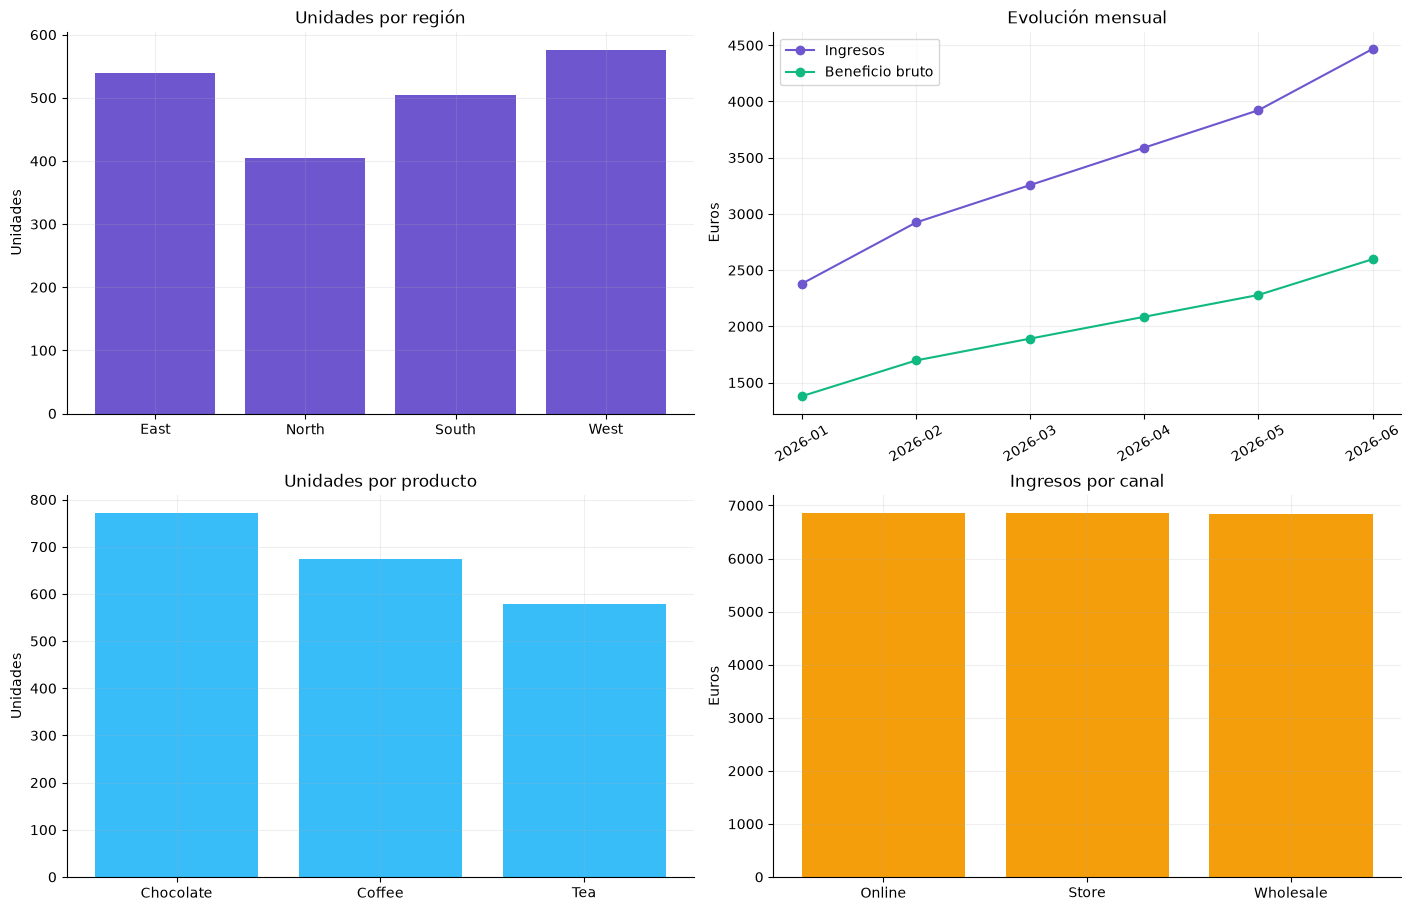

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
axes[0,0].bar(summary['region'], summary['units'], color='#6e56cf')
axes[0,0].set(title='Unidades por región', ylabel='Unidades')
if not monthly.empty:
    axes[0,1].plot(monthly['month'], monthly['revenue'], marker='o', label='Ingresos', color='#6e56cf')
    axes[0,1].plot(monthly['month'], monthly['profit'], marker='o', label='Beneficio bruto', color='#10b981')
    axes[0,1].legend()
else:
    axes[0,1].text(.5,.5,'Sin datos temporales', ha='center', transform=axes[0,1].transAxes)
axes[0,1].set(title='Evolución mensual', ylabel='Euros')
axes[0,1].tick_params(axis='x', rotation=30)
axes[1,0].bar(products['product'], products['units'], color='#38bdf8')
axes[1,0].set(title='Unidades por producto', ylabel='Unidades')
axes[1,1].bar(channels['channel'], channels['revenue'], color='#f59e0b')
axes[1,1].set(title='Ingresos por canal', ylabel='Euros')
if filtered.empty:
    fig.suptitle('No hay registros con estos filtros')
plt.show()

## 8. Del DataFrame a Recharts
Reflex necesita listas de diccionarios. Cada `data_key` de la gráfica identifica una clave de esos diccionarios. Ejemplo: el eje X lee `region` y las barras leen `units`.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: En `_refresh`, busca `self.monthly`, `self.products` y `self.channels` dentro de **líneas 154–183**, `_refresh`. En la **línea 531**, la gráfica regional recibe `summary`. Las claves de `to_dict('records')` deben coincidir con `data_key`.

In [8]:
chart_data = summary.to_dict(orient='records')
print(chart_data)
# Equivalente de Reflex (solo para leer, no se ejecuta aquí):
# rx.recharts.bar_chart(
#     rx.recharts.x_axis(data_key='region'),
#     rx.recharts.bar(data_key='units'),
#     data=PandasAppState.summary, width='100%', height=280,
# )

[{'region': 'East', 'units': 540}, {'region': 'North', 'units': 405}, {'region': 'South', 'units': 504}, {'region': 'West', 'units': 576}]


## 9. Comparar con el código real de Reflex
Creamos un estado de prueba sin iniciar un servidor y ejecutamos el mismo evento que el botón. Esta celda es de comprobación: no modifica el CSV ni la sesión del navegador. Si cambias las fórmulas en una de las dos versiones, estas comparaciones ayudan a detectar diferencias.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: **líneas 136–262**, `PandasAppState` reúne el estado y los eventos. La celda invoca `load_sample` y `apply_filters` y compara sus resultados con los DataFrames del notebook; esta comprobación no tiene un equivalente visual en la app.

In [9]:
state = PandasAppState(_reflex_internal_init=True)
state.load_sample(False)
assert not state.error, state.error
state.apply_filters({'region': region, 'product': product})
assert state.matching_count == len(filtered)
assert state.total_units == int(filtered['units'].sum())
assert state.summary == summary.to_dict('records')
assert state.products == products.to_dict('records')
assert state.monthly == monthly[['month', 'revenue', 'profit']].to_dict('records')
assert state.channels == channels[['channel', 'revenue']].to_dict('records')
assert state.revenue == f"{filtered['revenue_cents'].sum()/100:.2f} €"
assert state.profit == f"{filtered['profit_cents'].sum()/100:.2f} €"
preview, actual_summary, count, units = analyze_orders(records, region, product)
assert len(preview) <= 50 and count == len(filtered)
print('Correcto: notebook y Reflex producen los mismos resultados.')

Correcto: notebook y Reflex producen los mismos resultados.


## 10. Prácticas para desarrollar en paralelo

1. Pon `region = 'North'` y `product = 'Tea'`: deben quedar seis pedidos.
2. Busca un producto inexistente: indicadores a cero y gráficas sin barras.
3. Añade al CSV una venta con precio inferior al coste y observa el beneficio.
4. Crea una agrupación de beneficio por producto. Primero compruébala aquí y después añádela en `_refresh` y en `extra_charts`.
5. Cambia colores y etiquetas: `color` en Matplotlib equivale a `fill` de las barras o `stroke` de las líneas en Recharts.

**Rutina:** explorar en el notebook → verificar el resultado → trasladar a Reflex → comparar ambas versiones. El cuaderno es una explicación ejecutable, no una sincronización automática de las celdas con el archivo Python.

> **Equivalente en Reflex** — `Ejercicio991Reflex/pandas_data_app.py`: Busca los comentarios `NOTEBOOK §…` en el archivo Python para volver al paso correspondiente. Los números de línea son una fotografía de esta versión y pueden desplazarse cuando añadas código.